# 팔머 펭귄 데이터 시각화 (seaborn 프로젝트)
동국대 AI캠퍼스 · seaborn 프로젝트 예제

- 데이터: **Palmer Penguins** (남극 팔머기지에서 실제 관측한 펭귄 생태 데이터, seaborn 내장)
- 흐름: 문제정의 → 데이터 준비 → 개수/비교 → 분포 → 관계 → 결론

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------
# 한글 폰트 설정 (OS 자동 감지)
# ---------------------------------------
import platform
_os = platform.system()
if _os == 'Windows':
    plt.rc('font', family='Malgun Gothic')     # 윈도우
elif _os == 'Darwin':
    plt.rc('font', family='AppleGothic')        # 맥
else:
    plt.rc('font', family='NanumGothic')        # 리눅스 / 구글 코랩
plt.rc('axes', unicode_minus=False)
plt.rc('figure', figsize=(6, 4))

## 문제 정의
- 펭귄은 **종(species)마다 생김새**(부리·날개·몸무게)가 얼마나 다를까?
- 두 측정값 사이에는 어떤 **관계**가 있을까?
- **측정값만으로 종을 구분**할 수 있을까? (→ 뒤에 배울 머신러닝 분류의 예고편)

## 데이터 준비
- 3개 종: **Adelie · Chinstrap · Gentoo**
- 측정값: 부리 길이/깊이, 날개 길이, 몸무게, 성별, 서식 섬
- 결측치가 몇 개 있어 `dropna()`로 제거

In [2]:
# seaborn 내장 실측 데이터 불러오기

# 👉 여기에 코드를 작성하세요
penguins = sns.load_dataset('penguins')
penguins = penguins.dropna()   # 결측치 제거
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


In [3]:
# 종별 개체 수 확인

# 👉 여기에 코드를 작성하세요
penguins.value_counts('species')

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

## 1. 개수 세기 — countplot

<Axes: xlabel='species', ylabel='count'>

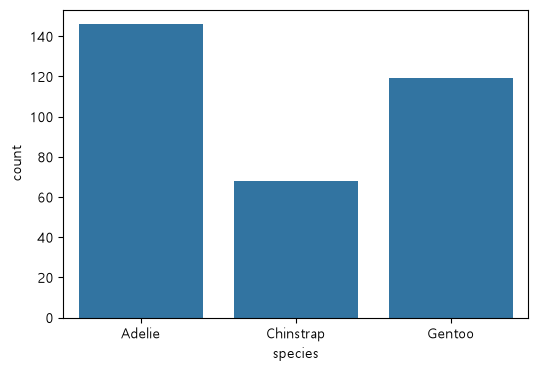

In [ ]:
# 👉 여기에 코드를 작성하세요

sns.countplot(data=penguins, x='species')
pass

## 2. 종별 몸무게 비교 — barplot · boxplot

<Axes: xlabel='species', ylabel='body_mass_g'>

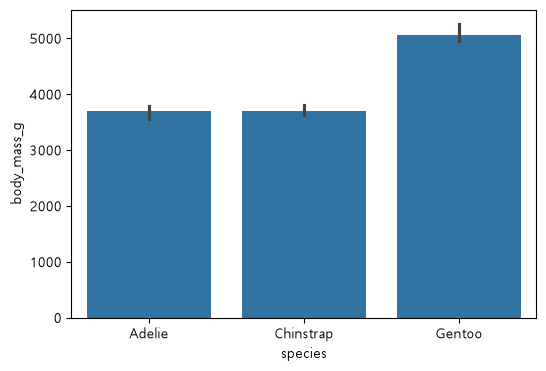

In [6]:
# 평균 비교 (막대)

# 👉 여기에 코드를 작성하세요
sns.barplot(data=penguins, x='species', y='body_mass_g', estimator='median')

<Axes: xlabel='species', ylabel='body_mass_g'>

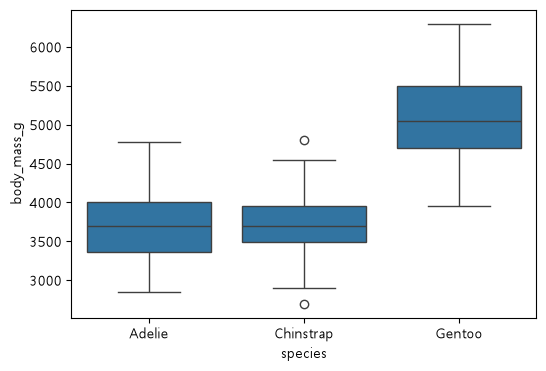

In [7]:
# 분포까지 비교 (상자그림) — Gentoo가 확연히 무겁다

# 👉 여기에 코드를 작성하세요

sns.boxplot(data=penguins, x='species', y='body_mass_g')


## 3. 분포 — histplot · violinplot

<Axes: xlabel='body_mass_g', ylabel='Count'>

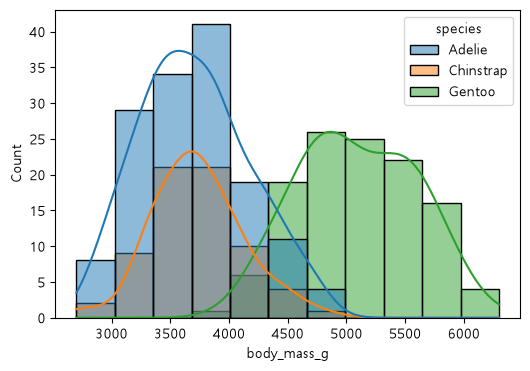

In [10]:
# 몸무게 분포를 종별로 겹쳐 보기

# 👉 여기에 코드를 작성하세요
sns.histplot(data=penguins, x='body_mass_g', hue='species', kde=True)

<Axes: ylabel='body_mass_g'>

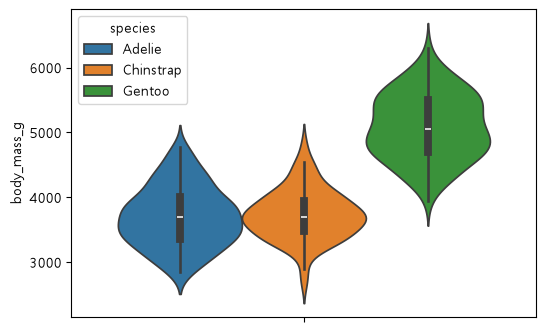

In [12]:
# 날개 길이 분포 (바이올린)

# 👉 여기에 코드를 작성하세요

sns.violinplot(data=penguins, y='body_mass_g', hue='species')

## 4. 관계 — scatterplot 과 '심슨의 역설'
부리 길이와 부리 깊이의 관계를 보자. **먼저 종 구분 없이** 전체로 그려본다.

In [16]:
penguins[['bill_length_mm','bill_depth_mm']].corr()

,bill_length_mm,bill_depth_mm
bill_length_mm,1.000000,-0.228626
bill_depth_mm,-0.228626,1.000000


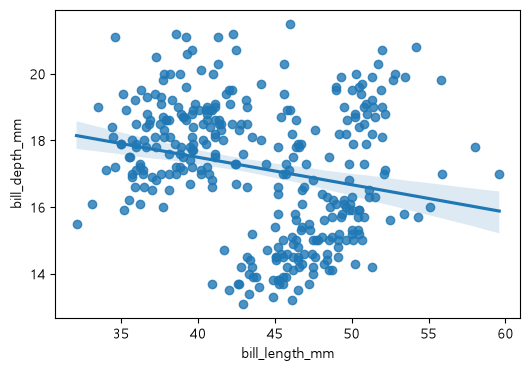

In [15]:
# 종 구분 없이 → 음의 상관(길수록 얕다)처럼 보인다

# 👉 여기에 코드를 작성하세요

sns.regplot(data=penguins, x='bill_length_mm', y='bill_depth_mm')
pass

> 전체로 보면 **음의 상관**처럼 보인다. 그런데 **종별로 색을 나누면** 어떻게 될까?

<Axes: xlabel='bill_length_mm', ylabel='bill_depth_mm'>

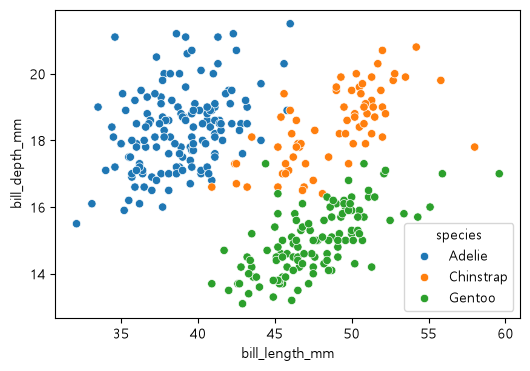

In [18]:
# hue로 종을 나누면 → 각 종 '안에서는' 양의 상관!

# 👉 여기에 코드를 작성하세요
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species')


> **심슨의 역설(Simpson's paradox)** — 전체 경향과 그룹별 경향이 반대로 나타나는 현상.
> 그래서 데이터는 **적절한 기준(hue)으로 나눠서** 봐야 한다.

## 5. 회귀 — regplot
날개 길이와 몸무게는 뚜렷한 양의 상관.

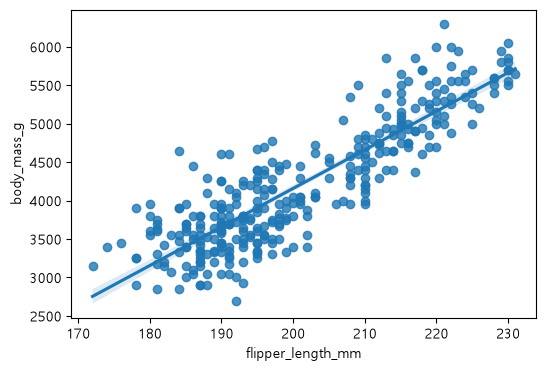

In [20]:
# 👉 여기에 코드를 작성하세요

sns.regplot(data=penguins, x='flipper_length_mm', y='body_mass_g')
pass

## 6. 상관 히트맵 — heatmap

<Axes: >

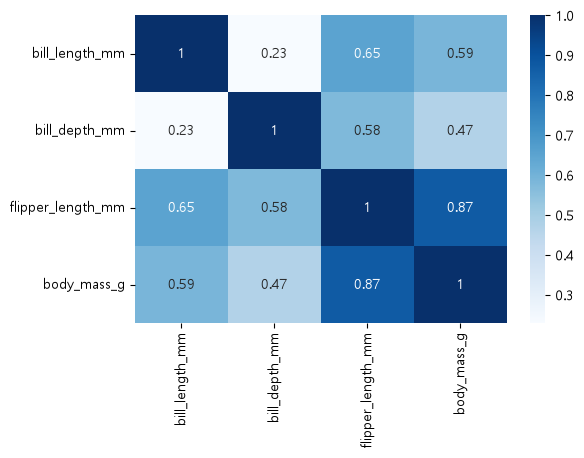

In [24]:
# 👉 여기에 코드를 작성하세요
corr = penguins.iloc[:,2:6].corr().abs()

sns.heatmap(corr, cmap='Blues', annot=True)

## 7. 한눈에 보기 — pairplot
모든 측정값 조합을 종(species)별 색으로.

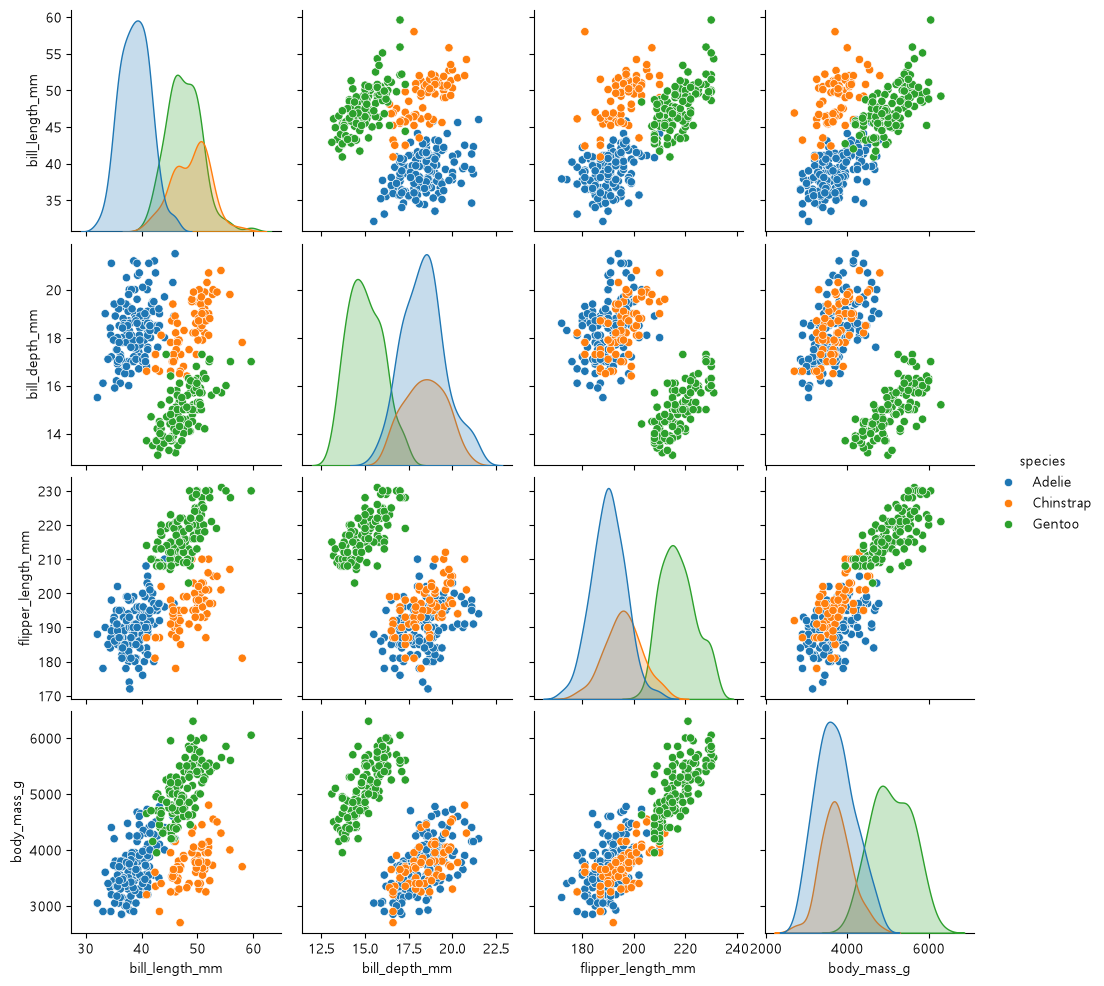

In [26]:
# 👉 여기에 코드를 작성하세요

sns.pairplot(penguins, hue='species')

> pairplot에서 **종끼리 뚜렷하게 무리(군집)** 지어 나뉜다.
> 즉 **측정값만으로 종을 구분할 수 있다** → 기계가 자동으로 분류하는 **머신러닝 분류(classification)**의 출발점.

## 결론
- 펭귄은 **종마다 몸무게·부리·날개 특징이 뚜렷이 다르다**(예: Gentoo가 가장 무겁고 날개가 길다).
- 부리 길이·깊이는 전체로 보면 음의 상관 같지만, **종별로 보면 양의 상관** → **심슨의 역설**. 데이터는 나눠서 봐야 한다.
- 날개 길이와 몸무게는 강한 양의 상관.
- **측정값만으로 종이 깔끔하게 갈린다**(pairplot) → 다음 단계인 **머신러닝 분류**로 자연스럽게 이어진다.